The first step is to analyze the dataset. My plan is to clean and select the amount of data to proceed with

title
catrogory 
bestseller

In [1]:
import pandas as pd
import numpy as np
import matplotlib as plt
import seaborn as sns
import sklearn as sk

In [2]:
#Licence - ODC Attribution License (ODC-By)

#@misc{asaniczka_2023,
# 	title={USA Optimal Product Price Prediction Dataset},
# 	url={https://www.kaggle.com/ds/3893031},
# 	DOI={10.34740/KAGGLE/DS/3893031},
# 	publisher={Kaggle},
# 	author={Asaniczka},
# 	year={2023}
# }

df = pd.read_csv("amz_us_price_prediction_dataset.csv")
df.head()

,uid,asin,title,stars,reviews,price,category,isBestSeller,boughtInLastMonth
0,1,B014TMV5YE,"Sion Softside Expandable Roller Luggage, Black...",4.5,0,139.99,Suitcases,False,2000
1,2,B07GDLCQXV,Luggage Sets Expandable PC+ABS Durable Suitcas...,4.5,0,169.99,Suitcases,False,1000
2,3,B07XSCCZYG,Platinum Elite Softside Expandable Checked Lug...,4.6,0,365.49,Suitcases,False,300
3,4,B08MVFKGJM,Freeform Hardside Expandable with Double Spinn...,4.6,0,291.59,Suitcases,False,400
4,5,B01DJLKZBA,Winfield 2 Hardside Expandable Luggage with Sp...,4.5,0,174.99,Suitcases,False,400


In [3]:
df.shape

(1735414, 9)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1735414 entries, 0 to 1735413
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               object 
 2   title              object 
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   category           object 
 7   isBestSeller       bool   
 8   boughtInLastMonth  int64  
dtypes: bool(1), float64(2), int64(3), object(3)
memory usage: 107.6+ MB


In [5]:
df.isnull().sum()

uid                  0
asin                 0
title                1
stars                0
reviews              0
price                0
category             0
isBestSeller         0
boughtInLastMonth    0
dtype: int64

In [6]:
df = df.dropna() #removed all null values

In [7]:
df.duplicated(keep = False).sum() #checking for duplicates

np.int64(0)

In [8]:
print(df.duplicated(["asin", "title", "price", "category"], keep = False).value_counts())

print(df.duplicated(["asin", "title", "price", "category"]).value_counts())

False    1735413
Name: count, dtype: int64
False    1735413
Name: count, dtype: int64


In [9]:
df.drop("uid", axis = 1, inplace = True)
df.drop("asin", axis = 1, inplace = True)

In [10]:
df.head()

,title,stars,reviews,price,category,isBestSeller,boughtInLastMonth
0,"Sion Softside Expandable Roller Luggage, Black...",4.5,0,139.99,Suitcases,False,2000
1,Luggage Sets Expandable PC+ABS Durable Suitcas...,4.5,0,169.99,Suitcases,False,1000
2,Platinum Elite Softside Expandable Checked Lug...,4.6,0,365.49,Suitcases,False,300
3,Freeform Hardside Expandable with Double Spinn...,4.6,0,291.59,Suitcases,False,400
4,Winfield 2 Hardside Expandable Luggage with Sp...,4.5,0,174.99,Suitcases,False,400


In [11]:
df["price"].describe()
#average price is 4.2 


count    1.735413e+06
mean     4.220254e+01
std      1.249822e+02
min      0.000000e+00
25%      1.199000e+01
50%      1.989000e+01
75%      3.500000e+01
max      1.973181e+04
Name: price, dtype: float64

In [12]:
outliers = df[df["price"] == 0]
print(outliers[:10])

                                                 title  stars  reviews  price  \
177  Airconic Hardside Expandable Luggage with Spin...    3.8        0    0.0   
180  4 KIX 2.0 Softside Expandable Luggage with Spi...    4.5        0    0.0   
252  OCEAN HOLIDAY Luggage with Double Spinner Whee...    0.0        0    0.0   
328  Merge Short Trip Expandable Packing Case Mediu...    3.9        0    0.0   
445  Suitcase Caster, 1 Pair Luggage Swivel Wheels ...    4.0        0    0.0   
461  920 Heavy Duty Protective Dry Box Case With Ac...    4.8        0    0.0   
480                           Tranverz L - Sunday Grey    4.8        0    0.0   
518  Capri 2.0 27"-Inch Spinner - Expandable Luxury...    5.0        0    0.0   
570                           Tranverz M - Sunday Grey    4.8        0    0.0   
673  Voyages Hardside Luggage with Spinner Wheels, ...    0.0        0    0.0   

      category  isBestSeller  boughtInLastMonth  
177  Suitcases         False                  0  
180  Sui

In [13]:
df = df[df["price"] > 0.0]
df.shape

(1697655, 7)

In [14]:
col = df.columns

<Axes: xlabel='price'>

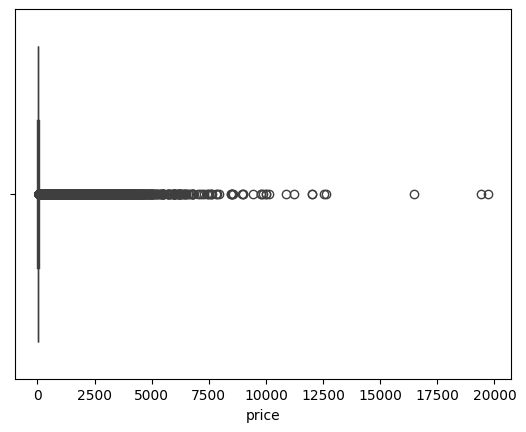

In [21]:
sns.boxplot(x = df["price"])

In [27]:
import matplotlib.pyplot as plot
def check_outliers(data, col):
    #calculating quantiles
    q25 = data[col].quantile(q = 0.25)
    q75 = data[col].quantile(q = 0.75)
    
    #calculating inter quantile range
    iqr = q75-q25
    
    #calculating upper_bound and lower_bound
    lower_bound = q25 - (1.5*iqr)
    upper_bound = q75 + (1.5*iqr)
    
    
    
    #filtering out outliers....!!!!!
    outliers = data[col][(data[col] < lower_bound) | (data[col] > upper_bound)]
    
    print("**** Printing Outliers Result ****")
    print("Printing bounds: ", lower_bound, upper_bound)
    print("\nTotal Outliers Present in the Data: %s"%(len(outliers)))
    
    #plotting the line plot result
    plot.figure(figsize=(10,10))
    plot.subplot(211)
    plot.plot(data[col])
    plot.title(col + " with Outliers")
    plot.scatter(x = outliers.index, y = outliers.values, marker = "X", color = 'r', s = 100)
    
    
    #plotting the box plot result
    plot.subplot(212)
    plot.title(col + " After Removing Extreme Values")
    filter_data = data[col][~(data[col].isin(outliers))]    
    sns.boxplot(filter_data)

**** Printing Outliers Result ****
Printing bounds:  -24.009999999999998 71.99000000000001

Total Outliers Present in the Data: 187074


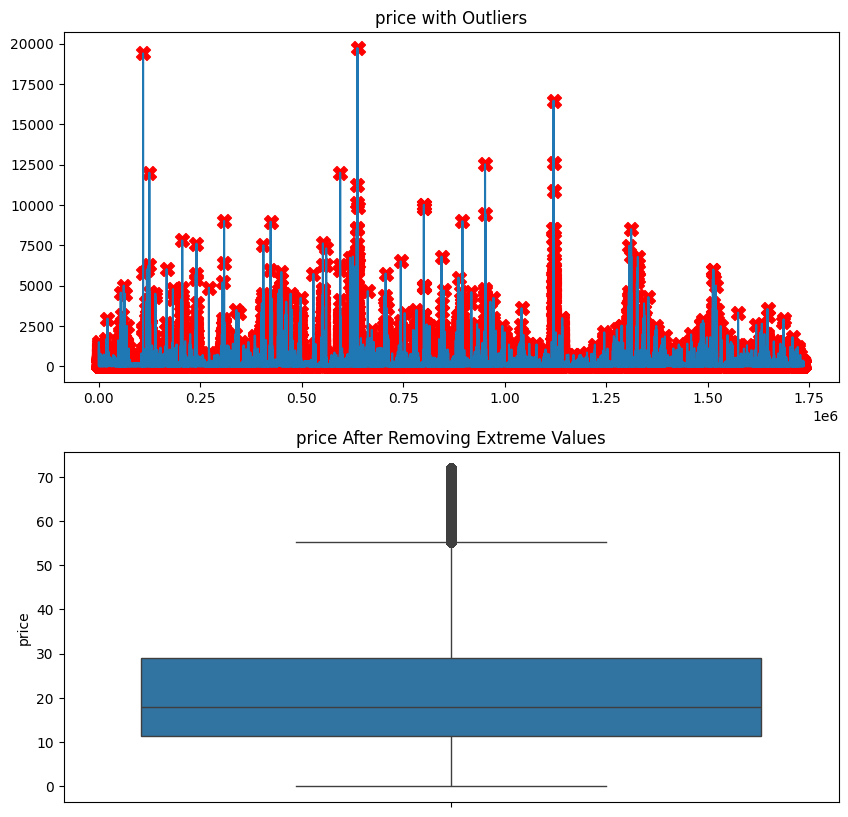

In [28]:
check_outliers(df, col[3])


The question is: remove the outliers from the dataset or not? If we are predicting the price?

In [41]:
outliers = df[df["price"] > 72]
print(len(outliers))
outliers = df[df["price"] < 72]
print(len(outliers))
outliers = df[df["price"] < 2]
print(len(outliers))


186857
1510581
1500


In [50]:
outliers = df[df["price"]  > 10500]
print(outliers)
print(len(outliers))

                                                     title  stars  reviews  \
108964                                    replicas Marinas    0.0        0   
124414   Sony VPL-XW6000ES 4K HDR Laser Home Theater Pr...    5.0        5   
594438   Sony VPL-XW6000ES 4K HDR Laser Home Theater Pr...    5.0        0   
637111            HPE MSA 2062 10GBASE-T iSCSI SFF Storage    0.0        0   
637194    Overland Storage Neoxl80 Storagelibrary Lto8 SAS    0.0        0   
951282   PARTNERS BRAND Corrugated Trash Can Plain - 40...    0.0        0   
1120106  CISCO Systems 1 Port ATM Enhanced Oc12/Stm4 Si...    0.0        0   
1120107  Cisco Systems 7140 Router Dual 10/100 Fe Dual ...    0.0        0   
1120126  CISCO Systems Catalyst 5000 Family Supervisor ...    0.0        0   

            price                       category  isBestSeller  \
108964   19400.00              Fabric Decorating         False   
124414   11998.00             Office Electronics         False   
594438   11998.00    

In [ ]:
# df = df[df["price"] < 12500]
# df.shape

(1697650, 7)

In [ ]:
category_counts = df["category"].value_counts()
print(category_counts)

category
Games & Accessories                      29044
Girls' Clothing                          28355
Toys & Games                             27383
Boys' Clothing                           24475
Consoles & Accessories                   21304
                                         ...  
Online Video Game Services                  99
Smart Home: Vacuums and Mops                94
Smart Home: New Smart Devices               88
Smart Home: Lawn and Garden                 67
Smart Home: Voice Assistants and Hubs       35
Name: count, Length: 236, dtype: int64

Total Categories:  236


In [58]:
df["category"].value_counts().head(20) 

category
Games & Accessories            29044
Girls' Clothing                28355
Toys & Games                   27383
Boys' Clothing                 24475
Consoles & Accessories         21304
Men's Shoes                    18950
Women's Handbags               18779
Girls' Jewelry                 18441
Women's Clothing               18023
Men's Clothing                 17943
Women's Jewelry                17920
Men's Accessories              17579
Travel Accessories             17547
Women's Accessories            17258
Home Storage & Organization    17157
Accessories & Supplies         15672
Women's Shoes                  15525
Computers                      15198
Backpacks                      14043
Men's Watches                  13013
Name: count, dtype: int64

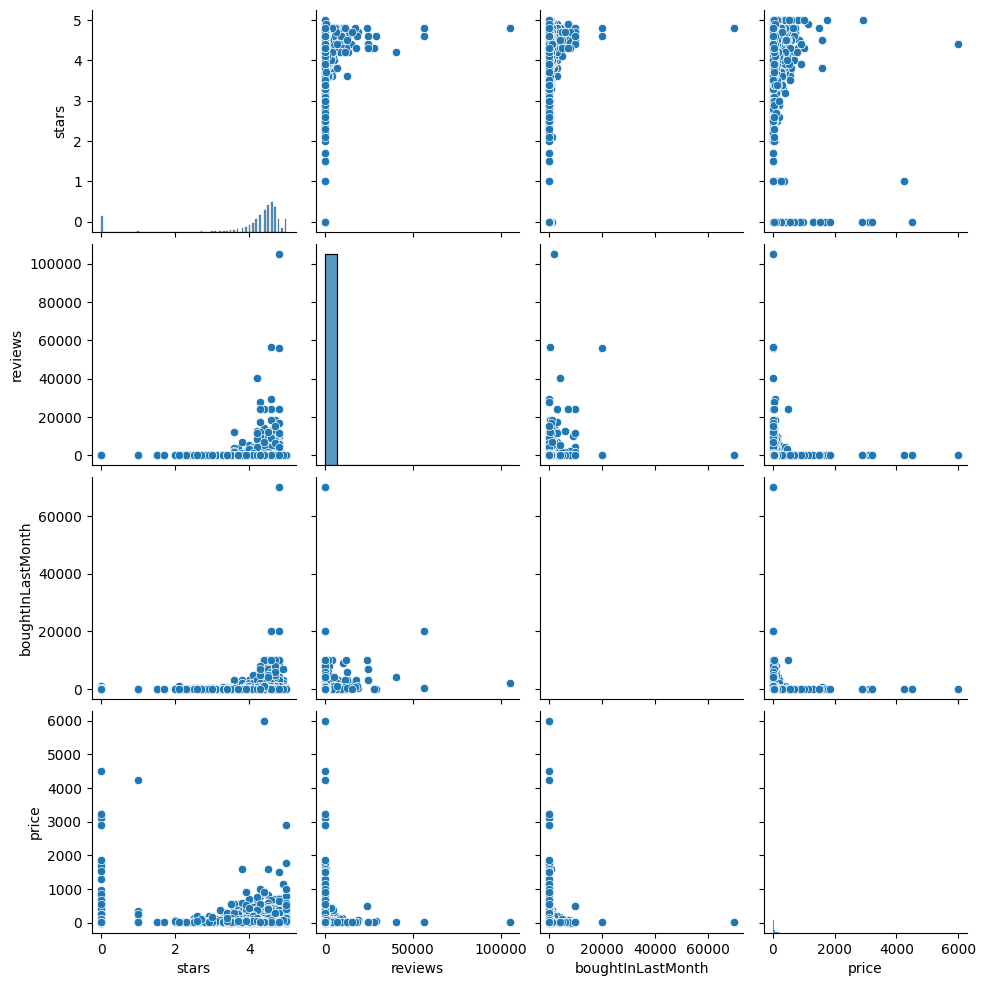

In [22]:
#Plotting the pairplot visualization 
#works only with the numerical values
#selected 10000 rows as an example
columns_to_plot = ["stars", "reviews", "boughtInLastMonth", "price"]
sns.pairplot(df[columns_to_plot].sample(10000))

Text(0.5, 1.0, 'Correlation Heatmap')

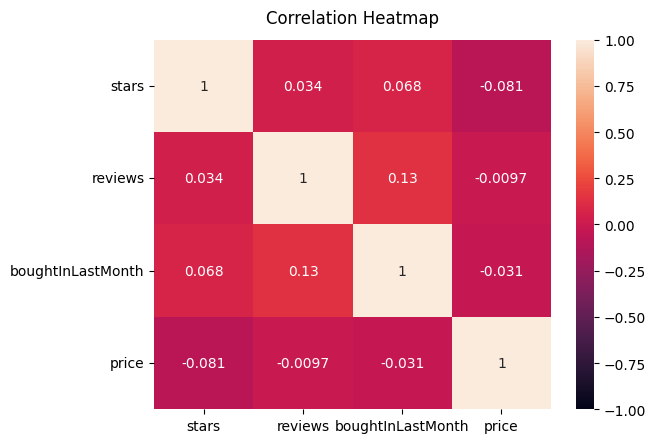

In [59]:
#Correlation matrix  to check relationship between variables
#if r = 0 no correlation, if r = 1 perfect correlation
corr_matrix = df[["stars", "reviews", "boughtInLastMonth", "price"]].corr()

heatmap = sns.heatmap(corr_matrix, vmin = -1, vmax = 1, annot = True)
heatmap.set_title("Correlation Heatmap", fontdict = {"fontsize": 12}, pad = 12)

For the price prediction:
As stars increase, price slightly decreases
but the relationship for the task is not meaningful 

In [60]:
df.drop("stars", axis = 1, inplace = True)
df.drop("reviews", axis = 1, inplace = True)
df.drop("boughtInLastMonth", axis = 1, inplace = True)

In [61]:
df.head()

,title,price,category,isBestSeller
0,"Sion Softside Expandable Roller Luggage, Black...",139.99,Suitcases,False
1,Luggage Sets Expandable PC+ABS Durable Suitcas...,169.99,Suitcases,False
2,Platinum Elite Softside Expandable Checked Lug...,365.49,Suitcases,False
3,Freeform Hardside Expandable with Double Spinn...,291.59,Suitcases,False
4,Winfield 2 Hardside Expandable Luggage with Sp...,174.99,Suitcases,False


In [62]:
df.to_csv("cleaned_amz_us_price_prediction_dataset.csv", index = False)